<a href="https://colab.research.google.com/github/dharanishree-p/FDS_RECORD/blob/main/06_Ex_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

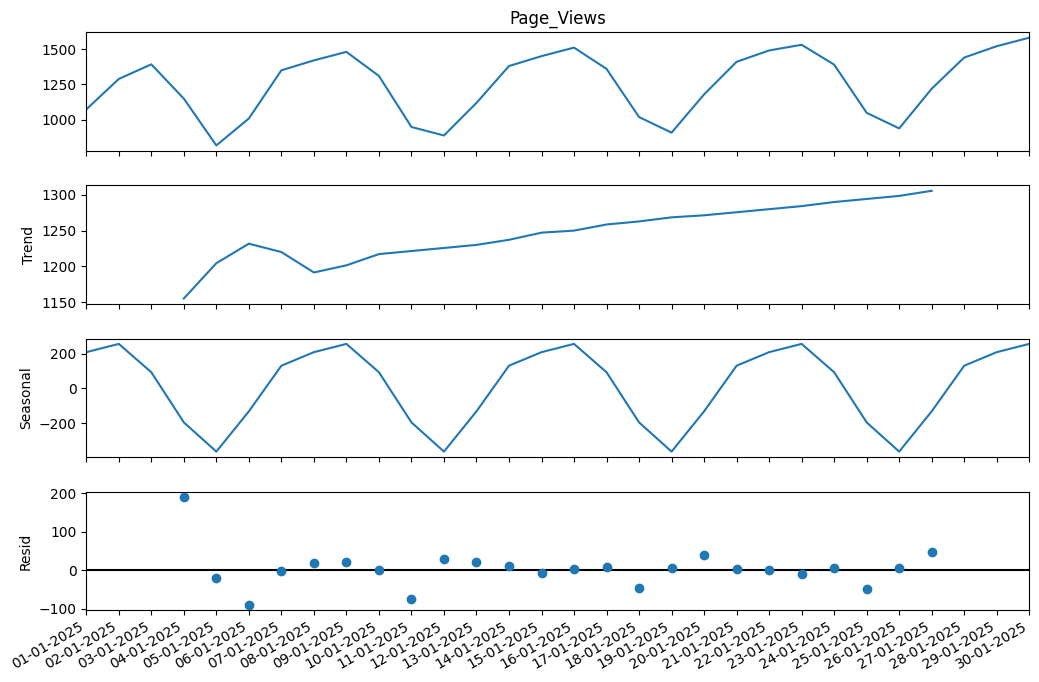

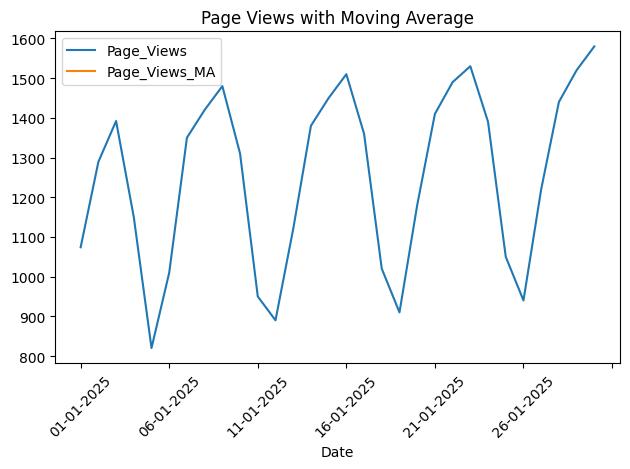

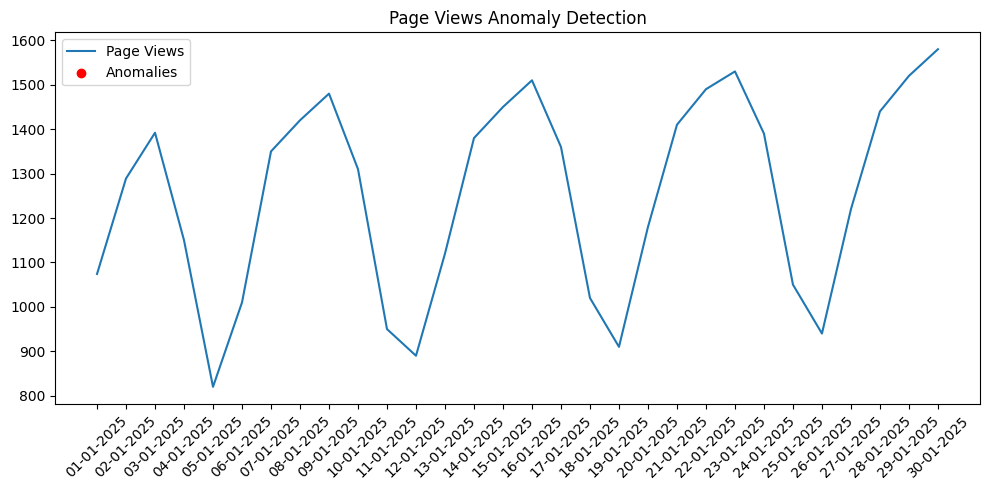

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
data = pd.read_csv('website_traffic - Sheet1 (1).csv', parse_dates=['Date'], index_col='Date')
decomposition = seasonal_decompose(data['Page_Views'], model='additive',period=7)
fig=decomposition.plot()
fig.set_size_inches(12,8)
fig.autofmt_xdate()
plt.show()
data['Page_Views_MA'] = data['Page_Views'].rolling(window=30).mean()
data[['Page_Views', 'Page_Views_MA']].plot()
plt.title('Page Views with Moving Average')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
data['Page_Views_Z'] = (data['Page_Views'] - data['Page_Views'].mean()) / data['Page_Views'].std()
anomalies = data[data['Page_Views_Z'].abs() > 3]
plt.figure(figsize=(10,5))
plt.plot(data.index, data['Page_Views'], label='Page Views')
plt.scatter(anomalies.index, anomalies['Page_Views'], color='red', label='Anomalies')
plt.xticks(rotation=45)
plt.title('Page Views Anomaly Detection')
plt.legend()
plt.tight_layout()
plt.show()